# Comparación de modelos

## 1. Datos y partición

In [ ]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler

sns.set_style("darkgrid")
warnings.filterwarnings("ignore")

SEMILLA = 42
FRACCION = 0.40   # revisamos al 40 % de los adultos
META = 0.75       # recall que queremos

RUTA_RAW = Path("..") / "data" / "raw"
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
df = pd.read_csv(RUTA_RAW / "NHANES_consolidado.csv")
print(df.shape)
df.head()

(9763, 12)


,Diabetes,Edad,Genero,Raza_Etnia,Ingreso_Hogar,Ingreso_Familia,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
0,1,69.0,1.0,4.0,4.0,4.0,26.7,100.0,122.0,72.0,167.0,65.0
1,1,54.0,1.0,3.0,7.0,7.0,28.6,107.6,156.0,62.0,170.0,50.0
2,1,72.0,1.0,3.0,10.0,10.0,28.9,109.2,140.0,90.0,126.0,60.0
3,0,9.0,1.0,3.0,9.0,9.0,17.1,61.0,108.0,38.0,168.0,61.0
4,0,73.0,2.0,3.0,15.0,15.0,19.7,NaN,136.0,86.0,201.0,85.0


In [ ]:
#Solo adultos
adultos = df[df["Edad"] >= 18].copy()
print("adultos:", adultos.shape)
print(adultos["Diabetes"].value_counts())
print(adultos["Diabetes"].value_counts(normalize=True).round(3))

adultos: (6110, 12)
Diabetes
0    5208
1     902
Name: count, dtype: int64
Diabetes
0    0.852
1    0.148
Name: proportion, dtype: float64


In [ ]:
print("diastólica menor a 10:", (adultos["Presion_Diastolica"] < 10).sum())
adultos.loc[adultos["Presion_Diastolica"] < 10, "Presion_Diastolica"] = np.nan
print("diastólica mínima ahora:", adultos["Presion_Diastolica"].min())

adultos["Genero_Mujer"] = (adultos["Genero"] == 2).astype(int)
print(adultos[["Genero", "Genero_Mujer"]].value_counts())

diastólica menor a 10: 32
diastólica mínima ahora: 22.0
Genero  Genero_Mujer
2.0     1               3194
1.0     0               2916
Name: count, dtype: int64


In [ ]:
VARS_8 = ["Edad", "Genero_Mujer", "IMC", "Cintura_cm", "Presion_Sistolica",
          "Presion_Diastolica", "Colesterol_Total", "Colesterol_HDL"]
VARS_6 = ["Edad", "Genero_Mujer", "IMC", "Presion_Sistolica", "Colesterol_Total", "Colesterol_HDL"]
CONTINUAS = [v for v in VARS_8 if v != "Genero_Mujer"]

X = adultos[VARS_8]
y = adultos["Diabetes"]
print(X.shape, y.shape)
X.head()

(6110, 8) (6110,)


,Edad,Genero_Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
0,69.0,0,26.7,100.0,122.0,72.0,167.0,65.0
1,54.0,0,28.6,107.6,156.0,62.0,170.0,50.0
2,72.0,0,28.9,109.2,140.0,90.0,126.0,60.0
4,73.0,1,19.7,NaN,136.0,86.0,201.0,85.0
5,56.0,0,41.7,123.1,160.0,84.0,226.0,38.0


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA)

print("train:", X_train.shape, "positivos:", y_train.sum(), "->", round(y_train.mean(), 3))
print("test: ", X_test.shape, "positivos:", y_test.sum(), "->", round(y_test.mean(), 3))

train: (4888, 8) positivos: 722 -> 0.148
test:  (1222, 8) positivos: 180 -> 0.147


In [ ]:
X_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train),
                     columns=VARS_8, index=X_train.index)
print("nulos antes:", X_train.isna().sum().sum())
print("nulos después:", X_imp.isna().sum().sum())
X_imp.head()

nulos antes: 2536
nulos después: 0


,Edad,Genero_Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
4400,38.0,1.0,31.2,104.0,118.0,72.0,200.0,40.0
6803,33.0,1.0,42.6,118.5,166.0,96.0,188.0,29.0
6528,60.0,1.0,28.2,102.7,120.0,72.0,178.0,63.0
2350,40.0,1.0,25.7,90.2,120.0,80.0,170.0,55.0
1087,32.0,0.0,35.7,106.9,116.0,64.0,210.0,63.0


## 2. Métricas

In [ ]:
def top_k(y_real, puntaje, fraccion=FRACCION):
    k = int(round(fraccion * len(y_real)))
    return np.argsort(-np.asarray(puntaje), kind="stable")[:k]

def recall_al_k(y_real, puntaje, fraccion=FRACCION):
    y_real = np.asarray(y_real)
    return y_real[top_k(y_real, puntaje, fraccion)].sum() / y_real.sum()

def precision_al_k(y_real, puntaje, fraccion=FRACCION):
    y_real = np.asarray(y_real)
    return y_real[top_k(y_real, puntaje, fraccion)].mean()

def metricas(y_real, puntaje):
    return {"ROC-AUC": roc_auc_score(y_real, puntaje),
            "PR-AUC": average_precision_score(y_real, puntaje),
            "Recall@40%": recall_al_k(y_real, puntaje),
            "Precision@40%": precision_al_k(y_real, puntaje)}

In [ ]:
rng = np.random.default_rng(0)
azar = rng.random(len(y_train))
perfecto = y_train.values + rng.random(len(y_train)) * 0.01

print("recall con puntaje al azar:", round(recall_al_k(y_train, azar), 3))
print("recall con puntaje perfecto:", round(recall_al_k(y_train, perfecto), 3))
print("precisión con puntaje al azar:", round(precision_al_k(y_train, azar), 3), "(prevalencia:", round(y_train.mean(), 3), ")")

recall con puntaje al azar: 0.407
recall con puntaje perfecto: 1.0
precisión con puntaje al azar: 0.15 (prevalencia: 0.148 )


## 3. Supuestos

In [ ]:
eventos = int(y_train.sum())
print("positivos en train:", eventos)

n_interacciones = PolynomialFeatures(2, include_bias=False).fit(np.zeros((1, 8))).n_output_features_
n_splines = 7 * (5 + 3 - 1) + 1   # 7 variables continuas x 7 funciones base + género
print("parámetros con interacciones:", n_interacciones)
print("parámetros con splines:", n_splines)

epv = pd.DataFrame({"parametros": {"Solo edad": 1, "LR 8 vars": 8, "LR 6 vars": 6,
                                    "LR interacciones": n_interacciones,
                                    "LR splines": n_splines, "LDA": 8}})
epv["positivos_por_parametro"] = (eventos / epv["parametros"]).round(1)
epv["cumple_10"] = epv["positivos_por_parametro"] >= 10
epv

positivos en train: 722
parámetros con interacciones: 44
parámetros con splines: 50


,parametros,positivos_por_parametro,cumple_10
Solo edad,1,722.0,True
LR 8 vars,8,90.2,True
LR 6 vars,6,120.3,True
LR interacciones,44,16.4,True
LR splines,50,14.4,True
LDA,8,90.2,True


### Independencia

In [ ]:
MEDIDAS = ["IMC", "Cintura_cm", "Presion_Sistolica", "Presion_Diastolica", "Colesterol_Total", "Colesterol_HDL"]
sin_medidas = adultos[MEDIDAS].isna().all(axis=1)

repetidas = adultos[adultos.duplicated(keep=False)]
print("filas idénticas:", len(repetidas))
print("de esas, sin ninguna medida clínica:", int(sin_medidas[repetidas.index].sum()))
print("adultos sin ninguna medida clínica:", int(sin_medidas.sum()), "->", round(sin_medidas.mean() * 100, 1), "%")
repetidas[["Edad", "Genero"] + MEDIDAS]

filas idénticas: 4
de esas, sin ninguna medida clínica: 4
adultos sin ninguna medida clínica: 193 -> 3.2 %


,Edad,Genero,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
2542,80.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
2998,80.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN
6115,80.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN
7948,80.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN


### Datos faltantes


In [ ]:
nulos = pd.DataFrame({"n_nulos": X_train.isna().sum(),
                      "pct_nulos": (X_train.isna().mean() * 100).round(1)})
nulos[nulos["n_nulos"] > 0]

,n_nulos,pct_nulos
IMC,218,4.5
Cintura_cm,423,8.7
Presion_Sistolica,560,11.5
Presion_Diastolica,587,12.0
Colesterol_Total,374,7.7
Colesterol_HDL,374,7.7


In [ ]:
filas = []
for v in VARS_8:
    falta = X_train[v].isna()
    if falta.sum() == 0:
        continue
    p_edad = stats.mannwhitneyu(X_train.loc[falta, "Edad"], X_train.loc[~falta, "Edad"]).pvalue
    p_casos = stats.chi2_contingency(pd.crosstab(falta, y_train))[1]
    filas.append({"variable": v,
                  "edad_media_con_dato": round(X_train.loc[~falta, "Edad"].mean(), 1),
                  "edad_media_sin_dato": round(X_train.loc[falta, "Edad"].mean(), 1),
                  "p_edad": round(p_edad, 4),
                  "pct_casos_con_dato": round(y_train[~falta].mean() * 100, 1),
                  "pct_casos_sin_dato": round(y_train[falta].mean() * 100, 1),
                  "p_casos": round(p_casos, 3)})
pd.DataFrame(filas).set_index("variable")

,edad_media_con_dato,edad_media_sin_dato,p_edad,pct_casos_con_dato,pct_casos_sin_dato,p_casos
variable,,,,,,
IMC,47.3,48.5,0.4574,14.8,14.7,1.000
Cintura_cm,46.9,52.4,0.0000,14.5,17.3,0.151
Presion_Sistolica,47.1,49.4,0.0065,14.6,16.4,0.266
Presion_Diastolica,47.0,49.8,0.0013,14.5,16.7,0.181
Colesterol_Total,47.4,46.5,0.2466,14.9,13.4,0.472
Colesterol_HDL,47.4,46.5,0.2466,14.9,13.4,0.472


In [ ]:
opciones = {
    "mediana": SimpleImputer(strategy="median"),
    "mediana + indicador": SimpleImputer(strategy="median", add_indicator=True),
    "iterativa": IterativeImputer(random_state=SEMILLA, max_iter=10),
    "vecinos (k=15)": KNNImputer(n_neighbors=15),
}
cv_imp = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)

filas = []
for nombre, imputador in opciones.items():
    modelo = make_pipeline(clone(imputador), StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
    for tr, va in cv_imp.split(X_train, y_train):
        m = clone(modelo).fit(X_train.iloc[tr], y_train.iloc[tr])
        filas.append({"imputación": nombre, **metricas(y_train.iloc[va], m.predict_proba(X_train.iloc[va])[:, 1])})
pd.DataFrame(filas).groupby("imputación", sort=False).mean().round(4)

,ROC-AUC,PR-AUC,Recall@40%,Precision@40%
imputación,,,,
mediana,0.7995,0.4091,0.7923,0.2926
mediana + indicador,0.7977,0.4046,0.7927,0.2928
iterativa,0.8019,0.4091,0.7992,0.2951
vecinos (k=15),0.8014,0.4126,0.7992,0.2951


### Multicolinealidad

In [ ]:
X_imp.corr().round(2)

,Edad,Genero_Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
Edad,1.00,0.00,0.06,0.20,0.42,0.07,0.11,0.08
Genero_Mujer,0.00,1.00,0.08,-0.07,-0.11,-0.09,0.08,0.28
IMC,0.06,0.08,1.00,0.86,0.11,0.13,0.05,-0.26
Cintura_cm,0.20,-0.07,0.86,1.00,0.18,0.15,0.06,-0.32
Presion_Sistolica,0.42,-0.11,0.11,0.18,1.00,0.40,0.10,-0.01
Presion_Diastolica,0.07,-0.09,0.13,0.15,0.40,1.00,0.17,-0.03
Colesterol_Total,0.11,0.08,0.05,0.06,0.10,0.17,1.00,0.18
Colesterol_HDL,0.08,0.28,-0.26,-0.32,-0.01,-0.03,0.18,1.00


In [ ]:
vif = {}
for v in VARS_8:
    otras = [o for o in VARS_8 if o != v]
    r2 = LinearRegression().fit(X_imp[otras], X_imp[v]).score(X_imp[otras], X_imp[v])
    vif[v] = 1 / (1 - r2)
pd.Series(vif, name="VIF").round(2).sort_values(ascending=False).to_frame()

,VIF
Cintura_cm,4.84
IMC,4.53
Presion_Sistolica,1.47
Edad,1.37
Colesterol_HDL,1.28
Presion_Diastolica,1.25
Genero_Mujer,1.20
Colesterol_Total,1.09


### Linealidad en logit

In [ ]:
Xbt = X_imp.copy()
for v in CONTINUAS:
    Xbt[v + "_xlnx"] = Xbt[v] * np.log(Xbt[v])

ajuste_bt = sm.Logit(y_train, sm.add_constant(Xbt)).fit(disp=0)
cols = [v + "_xlnx" for v in CONTINUAS]
bt = pd.DataFrame({"coef": ajuste_bt.params[cols].values, "p_valor": ajuste_bt.pvalues[cols].values},
                  index=CONTINUAS)
bt["lineal (p > 0.05/7)"] = bt["p_valor"] > 0.05 / 7
bt.round(4)

,coef,p_valor,lineal (p > 0.05/7)
Edad,-0.1418,0.0000,False
IMC,-0.0034,0.9482,True
Cintura_cm,-0.0524,0.1892,True
Presion_Sistolica,-0.0198,0.3813,True
Presion_Diastolica,-0.0141,0.6166,True
Colesterol_Total,0.0111,0.0009,False
Colesterol_HDL,0.0191,0.2148,True


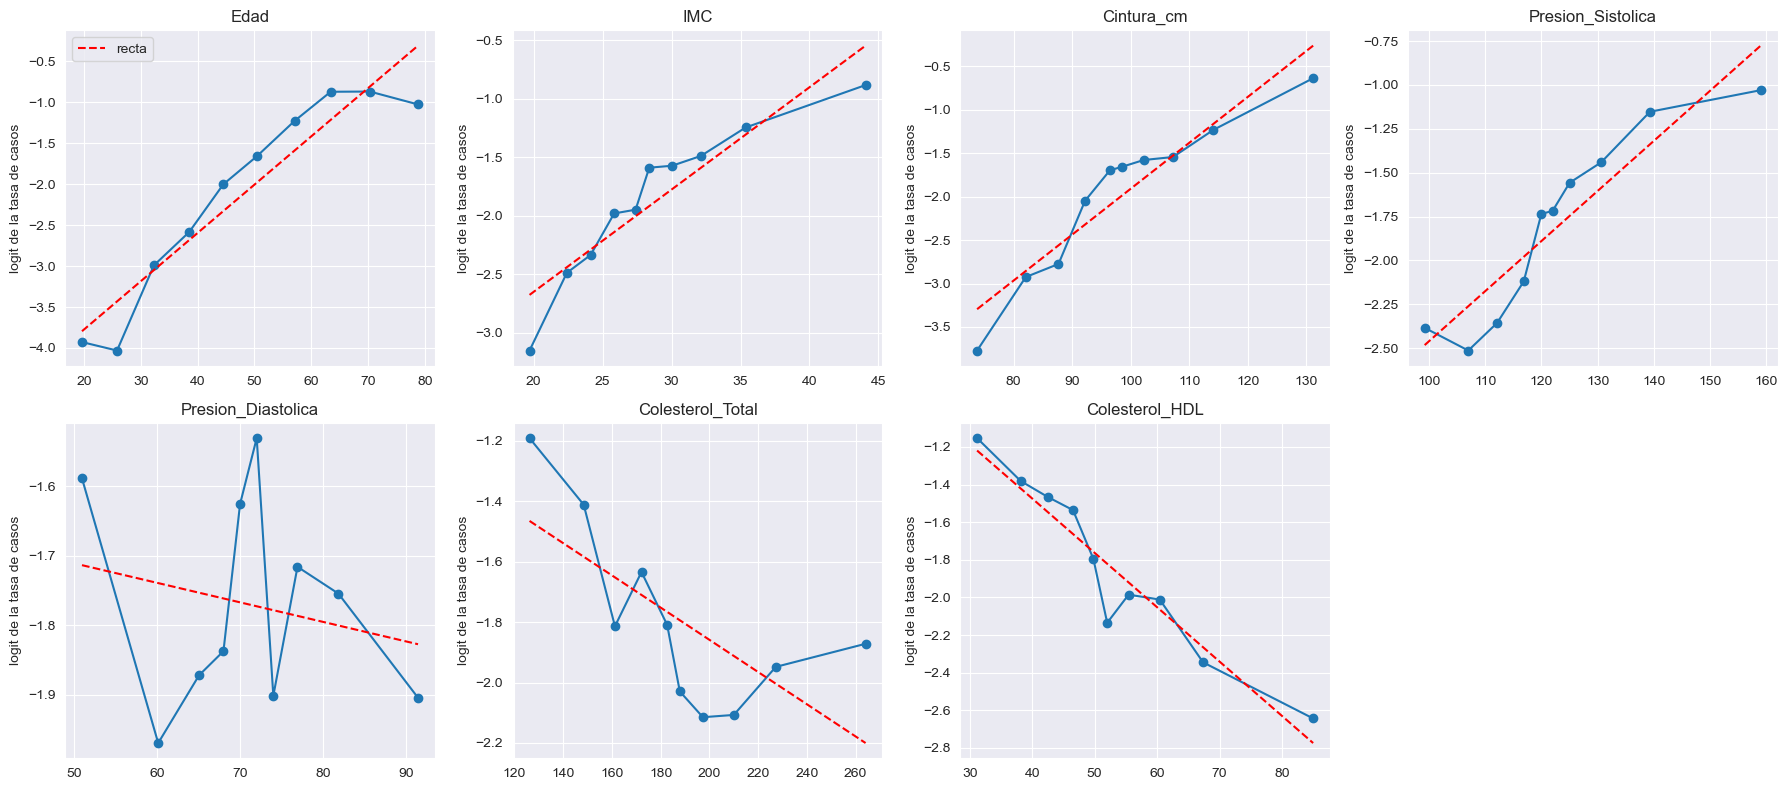

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, v in zip(axes.flatten(), CONTINUAS):
    tramos = pd.qcut(X_imp[v], 10, duplicates="drop")
    g = pd.DataFrame({"x": X_imp[v], "y": y_train}).groupby(tramos, observed=True).agg(x=("x", "mean"), p=("y", "mean"))
    p = g["p"].clip(0.005, 0.995)
    logit = np.log(p / (1 - p))
    ax.plot(g["x"], logit, "o-")
    pendiente, origen = np.polyfit(g["x"], logit, 1)
    ax.plot(g["x"], pendiente * g["x"] + origen, "--", color="red", label="recta")
    ax.set_title(v)
    ax.set_ylabel("logit de la tasa de casos")
axes.flatten()[-1].axis("off")
axes.flatten()[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "supuestos_linealidad_logit.png", dpi=150)
plt.show()

In [ ]:
glm = sm.GLM(y_train, sm.add_constant(X_imp), family=sm.families.Binomial()).fit()
cook = glm.get_influence().cooks_distance[0]
influyentes = cook > 4 / len(X_imp)
print("Cook máxima:", round(cook.max(), 4))
print("observaciones sobre 4/n:", influyentes.sum(), "->", round(influyentes.mean() * 100, 1), "%")

Cook máxima: 0.0263
observaciones sobre 4/n: 377 -> 7.7 %


In [ ]:
def lr_simple():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=0.1, max_iter=3000))

con_todos = lr_simple().fit(X_train, y_train)
sin_influyentes = lr_simple().fit(X_train[~influyentes], y_train[~influyentes])

pd.DataFrame({"con todos": metricas(y_test, con_todos.predict_proba(X_test)[:, 1]),
              "sin influyentes": metricas(y_test, sin_influyentes.predict_proba(X_test)[:, 1])}).round(3)

,con todos,sin influyentes
ROC-AUC,0.802,0.794
PR-AUC,0.396,0.400
Recall@40%,0.800,0.783
Precision@40%,0.294,0.288


### Normalidad y covarianzas iguales 

In [ ]:
filas = []
for v in CONTINUAS:
    for clase in (0, 1):
        s = X_imp.loc[y_train == clase, v]
        filas.append({"variable": v, "clase": clase,
                      "asimetria": stats.skew(s), "curtosis": stats.kurtosis(s)})
pd.DataFrame(filas).pivot(index="variable", columns="clase", values=["asimetria", "curtosis"]).round(2)

asimetria       curtosis      
clase                      0     1        0     1
variable                                         
Cintura_cm              0.74  0.73     1.25  0.44
Colesterol_HDL          1.28  1.31     3.77  4.27
Colesterol_Total        1.57  0.58    16.61  0.47
Edad                    0.29 -0.60    -1.00 -0.09
IMC                     1.48  1.12     4.46  1.81
Presion_Diastolica      0.09 -0.20     0.98  1.46
Presion_Sistolica       1.20  1.04     3.03  1.99

In [ ]:
def m_de_box(datos, etiquetas):
    clases = np.unique(etiquetas)
    p, k = datos.shape[1], len(clases)
    n_i = np.array([(etiquetas == cl).sum() for cl in clases])
    N = n_i.sum()
    S = [np.cov(datos[etiquetas == cl].T) for cl in clases]
    Sp = sum((n - 1) * s for n, s in zip(n_i, S)) / (N - k)
    M = (N - k) * np.linalg.slogdet(Sp)[1] - sum((n - 1) * np.linalg.slogdet(s)[1] for n, s in zip(n_i, S))
    c_ = (sum(1 / (n - 1) for n in n_i) - 1 / (N - k)) * (2 * p**2 + 3 * p - 1) / (6 * (p + 1) * (k - 1))
    estadistico = M * (1 - c_)
    gl = p * (p + 1) * (k - 1) / 2
    return estadistico, gl, stats.chi2.sf(estadistico, gl)

est, gl, p_box = m_de_box(X_imp[CONTINUAS].values, y_train.values)
print("M de Box:", round(est, 1), "| gl:", gl, "| p:", p_box)

# cociente de desviaciones estándar entre clases
(X_imp[CONTINUAS][y_train == 1].std() / X_imp[CONTINUAS][y_train == 0].std()).round(2).to_frame("sd clase1 / sd clase0")

M de Box: 615.1 | gl: 28.0 | p: 1.0002003846069797e-111


,sd clase1 / sd clase0
Edad,0.76
IMC,1.12
Cintura_cm,1.05
Presion_Sistolica,1.13
Presion_Diastolica,1.05
Colesterol_Total,1.02
Colesterol_HDL,0.85


## 4. Modelos y validación cruzada

Tests:
- solo edad (la línea base)
- regresión logística con pesos de clase (8 variables)
- regresión logística sin pesos (8 variables)
- regresión logística sin pesos (6 variables)
- regresión logística con interacciones
- regresión logística con splines
- LDA
- Random Forest
- Gradient Boosting

In [ ]:
def lr(pesos=None, C=1.0):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=C, class_weight=pesos, max_iter=3000))

def lr_interacciones():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         PolynomialFeatures(2, include_bias=False), StandardScaler(),
                         LogisticRegression(C=0.05, max_iter=5000))

def lr_splines():
    # splines en las 7 variables continuas (todas menos Genero_Mujer, que es la columna 1)
    spl = ColumnTransformer([("spl", SplineTransformer(n_knots=5, degree=3, extrapolation="linear"),
                              [0, 2, 3, 4, 5, 6, 7])], remainder="passthrough")
    return make_pipeline(SimpleImputer(strategy="median"), spl, StandardScaler(),
                         LogisticRegression(C=0.1, max_iter=5000))

def lda():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LinearDiscriminantAnalysis(solver="lsqr"))

def rf():
    return make_pipeline(SimpleImputer(strategy="median"),
                         RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEMILLA))

def hgb():
    return HistGradientBoostingClassifier(l2_regularization=1.0, random_state=SEMILLA)

# nombre: (variables, modelo, hiperparámetros a probar)
CANDIDATOS = {
    "Solo edad": (["Edad"], lr(), {"logisticregression__C": [1.0]}),
    "LR con pesos (8 vars)": (VARS_8, lr("balanced"), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "LR sin pesos (8 vars)": (VARS_8, lr(), {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "LR sin pesos (6 vars)": (VARS_6, lr(), {"logisticregression__C": [0.01, 0.1, 1, 10]}),
    "LR con interacciones": (VARS_8, lr_interacciones(), {"logisticregression__C": [0.003, 0.01, 0.05, 0.2]}),
    "LR con splines": (VARS_8, lr_splines(), {"logisticregression__C": [0.003, 0.01, 0.03, 0.1, 0.3]}),
    "LDA": (VARS_8, lda(), {"lineardiscriminantanalysis__shrinkage": [None, 0.1, 0.5, "auto"]}),
    "Random Forest": (VARS_8, rf(), {"randomforestclassifier__min_samples_leaf": [10, 20, 40],
                                      "randomforestclassifier__max_depth": [None, 6]}),
    "Gradient Boosting": (VARS_8, hgb(), {"learning_rate": [0.03, 0.05], "max_depth": [2, 3],
                                          "min_samples_leaf": [40]}),
}
print(len(CANDIDATOS), "modelos")
list(CANDIDATOS)

9 modelos


['Solo edad',
 'LR con pesos (8 vars)',
 'LR sin pesos (8 vars)',
 'LR sin pesos (6 vars)',
 'LR con interacciones',
 'LR con splines',
 'LDA',
 'Random Forest',
 'Gradient Boosting']

In [ ]:
cv_afinar = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
mejores = {}
filas = []
for nombre, (vars_, modelo, rejilla) in CANDIDATOS.items():
    busqueda = GridSearchCV(modelo, rejilla, scoring="average_precision", cv=cv_afinar)
    busqueda.fit(X_train[vars_], y_train)
    mejores[nombre] = busqueda.best_estimator_
    filas.append({"modelo": nombre, "mejores_parametros": str(busqueda.best_params_).split("__")[-1],
                  "PR-AUC_cv": round(busqueda.best_score_, 3)})
afinado = pd.DataFrame(filas).set_index("modelo")
afinado

,mejores_parametros,PR-AUC_cv
modelo,,
Solo edad,C': 1.0},0.262
LR con pesos (8 vars),C': 100},0.399
LR sin pesos (8 vars),C': 0.1},0.408
LR sin pesos (6 vars),C': 1},0.392
LR con interacciones,C': 0.01},0.432
LR con splines,C': 0.01},0.435
LDA,shrinkage': None},0.408
Random Forest,min_samples_leaf': 40},0.432
Gradient Boosting,"{'learning_rate': 0.05, 'max_depth': 3, 'min_s...",0.425


In [ ]:
cv_comparar = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
resultados_cv = []
for nombre, (vars_, _, _) in CANDIDATOS.items():
    Xt = X_train[vars_]
    for tr, va in cv_comparar.split(Xt, y_train):
        modelo = clone(mejores[nombre]).fit(Xt.iloc[tr], y_train.iloc[tr])
        puntaje = modelo.predict_proba(Xt.iloc[va])[:, 1]
        resultados_cv.append({"Modelo": nombre, **metricas(y_train.iloc[va], puntaje)})
resultados_cv = pd.DataFrame(resultados_cv)
print(resultados_cv.shape)
resultados_cv.head()

(135, 5)


,Modelo,ROC-AUC,PR-AUC,Recall@40%,Precision@40%
0,Solo edad,0.741473,0.267597,0.708333,0.260870
1,Solo edad,0.751935,0.270948,0.758621,0.281330
2,Solo edad,0.717593,0.248974,0.668966,0.248082
3,Solo edad,0.713289,0.237866,0.694444,0.255754
4,Solo edad,0.752772,0.285975,0.736111,0.271100


In [ ]:
tabla_cv = resultados_cv.groupby("Modelo", sort=False).agg(
    ROC_AUC=("ROC-AUC", "mean"), PR_AUC=("PR-AUC", "mean"),
    Recall_40=("Recall@40%", "mean"), Desv_recall=("Recall@40%", "std"),
    Precision_40=("Precision@40%", "mean"),
    pct_sobre_meta=("Recall@40%", lambda s: (s >= META).mean())).round(3)
tabla_cv

,ROC_AUC,PR_AUC,Recall_40,Desv_recall,Precision_40,pct_sobre_meta
Modelo,,,,,,
Solo edad,0.736,0.262,0.717,0.030,0.265,0.200
LR con pesos (8 vars),0.799,0.402,0.793,0.024,0.293,1.000
LR sin pesos (8 vars),0.799,0.409,0.792,0.029,0.293,0.867
LR sin pesos (6 vars),0.795,0.393,0.790,0.021,0.292,1.000
LR con interacciones,0.808,0.428,0.802,0.027,0.296,1.000
LR con splines,0.806,0.431,0.789,0.027,0.292,1.000
LDA,0.797,0.409,0.780,0.028,0.288,0.867
Random Forest,0.805,0.430,0.784,0.032,0.289,0.867
Gradient Boosting,0.802,0.421,0.781,0.021,0.288,0.867


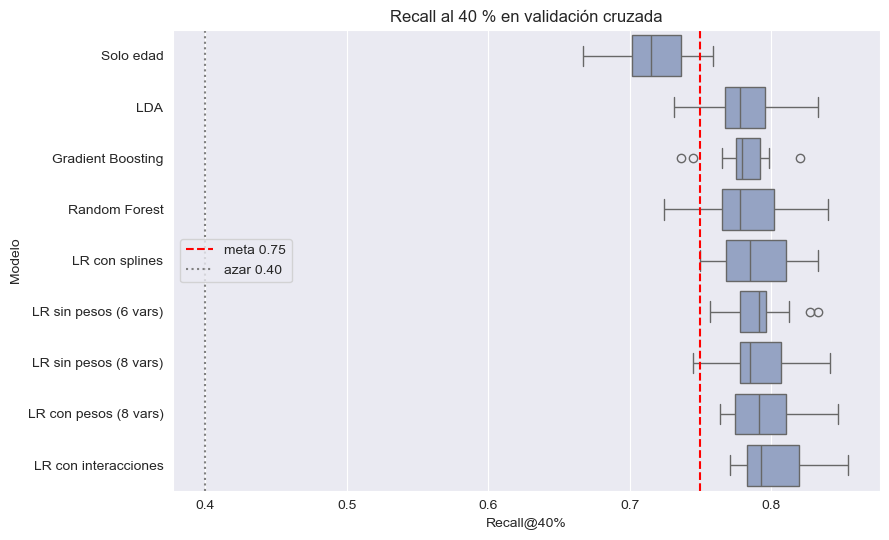

In [ ]:
orden = tabla_cv.sort_values("Recall_40").index
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=resultados_cv, y="Modelo", x="Recall@40%", order=orden, color="#8DA0CB", ax=ax)
ax.axvline(META, color="red", ls="--", label="meta 0.75")
ax.axvline(FRACCION, color="gray", ls=":", label="azar 0.40")
ax.set_title("Recall al 40 % en validación cruzada")
ax.legend(loc="center left")
plt.tight_layout()
plt.savefig(FIG_DIR / "modelos_recall_cv.png", dpi=150)
plt.show()

### Sobreajuste

In [ ]:
filas = []
for nombre in ["LR sin pesos (8 vars)", "LR con interacciones", "LR con splines", "LDA",
               "Random Forest", "Gradient Boosting"]:
    vars_ = CANDIDATOS[nombre][0]
    m = clone(mejores[nombre]).fit(X_train[vars_], y_train)
    auc_train = roc_auc_score(y_train, m.predict_proba(X_train[vars_])[:, 1])
    auc_cv = cross_val_score(clone(mejores[nombre]), X_train[vars_], y_train, cv=cv_afinar, scoring="roc_auc").mean()
    filas.append({"modelo": nombre, "auc_train": auc_train, "auc_cv": auc_cv, "brecha": auc_train - auc_cv})
pd.DataFrame(filas).set_index("modelo").round(3)

,auc_train,auc_cv,brecha
modelo,,,
LR sin pesos (8 vars),0.802,0.799,0.003
LR con interacciones,0.820,0.809,0.012
LR con splines,0.816,0.806,0.010
LDA,0.800,0.797,0.003
Random Forest,0.861,0.807,0.054
Gradient Boosting,0.851,0.804,0.047


## 5. Evaluación en prueba

In [ ]:
finales = {}
puntajes_test = {}
filas = []
for nombre, (vars_, _, _) in CANDIDATOS.items():
    modelo = clone(mejores[nombre]).fit(X_train[vars_], y_train)
    finales[nombre] = modelo
    puntajes_test[nombre] = modelo.predict_proba(X_test[vars_])[:, 1]
    filas.append({"Modelo": nombre, **metricas(y_test, puntajes_test[nombre])})
tabla_test = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla_test

,ROC-AUC,PR-AUC,Recall@40%,Precision@40%
Modelo,,,,
Solo edad,0.766,0.281,0.761,0.280
LR con pesos (8 vars),0.805,0.385,0.817,0.301
LR sin pesos (8 vars),0.802,0.396,0.800,0.294
LR sin pesos (6 vars),0.800,0.387,0.794,0.292
LR con interacciones,0.814,0.424,0.811,0.299
LR con splines,0.815,0.459,0.806,0.297
LDA,0.799,0.409,0.789,0.290
Random Forest,0.816,0.436,0.806,0.297
Gradient Boosting,0.814,0.434,0.811,0.299


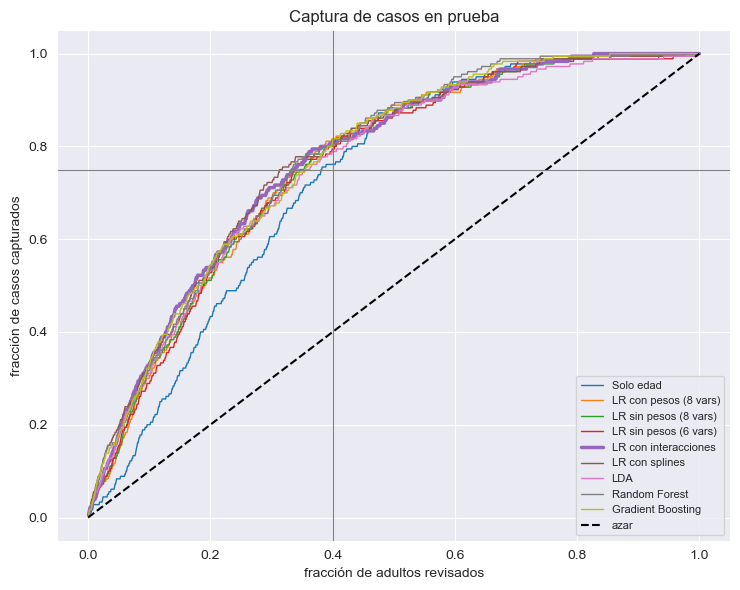

In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 6))
n = len(y_test)
for nombre, puntaje in puntajes_test.items():
    orden_ = np.argsort(-puntaje, kind="stable")
    acumulado = np.cumsum(y_test.values[orden_]) / y_test.sum()
    grosor = 2.5 if nombre == "LR con interacciones" else 1
    ax.plot(np.arange(1, n + 1) / n, acumulado, label=nombre, lw=grosor)
ax.plot([0, 1], [0, 1], "k--", label="azar")
ax.axvline(FRACCION, color="gray", lw=0.8)
ax.axhline(META, color="gray", lw=0.8)
ax.set_xlabel("fracción de adultos revisados")
ax.set_ylabel("fracción de casos capturados")
ax.set_title("Captura de casos en prueba")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "modelos_curva_captura_test.png", dpi=150)
plt.show()

### Final 


In [ ]:
ELEGIDO = "LR con interacciones"
vars_el = CANDIDATOS[ELEGIDO][0]
print("modelo elegido:", ELEGIDO)
print("variables:", vars_el)
print(afinado.loc[ELEGIDO])

modelo elegido: LR con interacciones
variables: ['Edad', 'Genero_Mujer', 'IMC', 'Cintura_cm', 'Presion_Sistolica', 'Presion_Diastolica', 'Colesterol_Total', 'Colesterol_HDL']
mejores_parametros    C': 0.01}
PR-AUC_cv                 0.432
Name: LR con interacciones, dtype: object


In [ ]:
oof = cross_val_predict(clone(finales[ELEGIDO]), X_train[vars_el], y_train, cv=cv_afinar,
                        method="predict_proba")[:, 1]
UMBRAL = float(np.quantile(oof, 1 - FRACCION))
print("umbral:", round(UMBRAL, 3))

p_test = puntajes_test[ELEGIDO]
prioriza = p_test >= UMBRAL
tp = int((prioriza & (y_test.values == 1)).sum())
fp = int((prioriza & (y_test.values == 0)).sum())
fn = int((~prioriza & (y_test.values == 1)).sum())
tn = int((~prioriza & (y_test.values == 0)).sum())
print("tp, fp, fn, tn:", tp, fp, fn, tn, "| total:", tp + fp + fn + tn, "| tamaño de prueba:", len(y_test))

pd.DataFrame([[tp, fn], [fp, tn]],
             index=["con diabetes/prediabetes", "sin diabetes/prediabetes"],
             columns=["priorizados", "no priorizados"])

umbral: 0.138
tp, fp, fn, tn: 144 324 36 718 | total: 1222 | tamaño de prueba: 1222


,priorizados,no priorizados
con diabetes/prediabetes,144,36
sin diabetes/prediabetes,324,718


In [ ]:
print("adultos priorizados:", round(prioriza.mean() * 100, 1), "%")
print("recall:", round(tp / (tp + fn), 3))
print("precisión:", round(tp / (tp + fp), 3))
print("especificidad:", round(tn / (tn + fp), 3))

# intervalo del recall al 40 % con bootstrap
rng = np.random.default_rng(SEMILLA)
yv, pv = y_test.values, p_test
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(yv), len(yv))
    boot.append(recall_al_k(yv[idx], pv[idx]))
bajo, alto = np.percentile(boot, [2.5, 97.5])
print("recall@40% en prueba:", round(recall_al_k(yv, pv), 3), "| intervalo 95 %:", round(bajo, 3), "a", round(alto, 3))

adultos priorizados: 38.3 %
recall: 0.8
precisión: 0.308
especificidad: 0.689


recall@40% en prueba: 0.811 | intervalo 95 %: 0.753 a 0.862


### Calibración

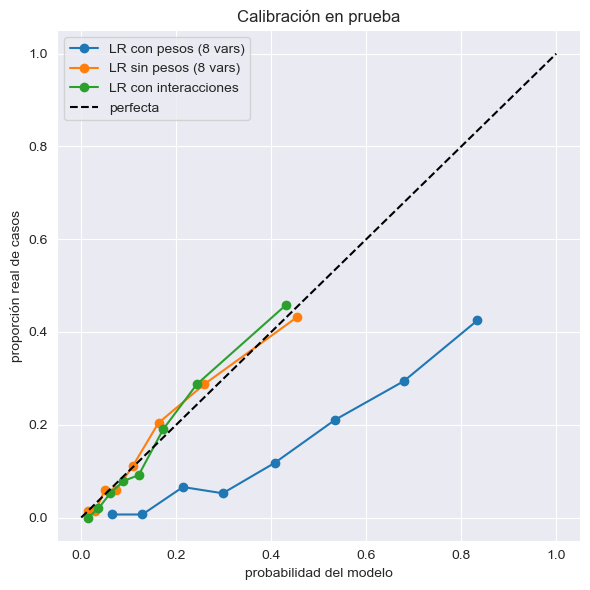

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
for nombre in ["LR con pesos (8 vars)", "LR sin pesos (8 vars)", "LR con interacciones"]:
    real, predicha = calibration_curve(y_test, puntajes_test[nombre], n_bins=8, strategy="quantile")
    ax.plot(predicha, real, marker="o", label=nombre)
ax.plot([0, 1], [0, 1], "k--", label="perfecta")
ax.set_xlabel("probabilidad del modelo")
ax.set_ylabel("proporción real de casos")
ax.set_title("Calibración en prueba")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "modelos_calibracion.png", dpi=150)
plt.show()

### Coeficientes


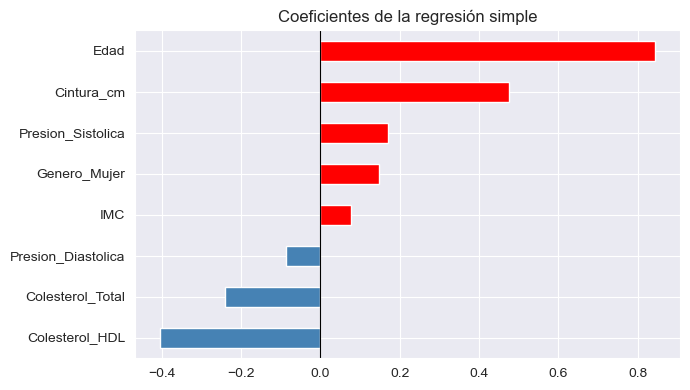

,coeficiente,odds_ratio
Edad,0.844,2.326
Cintura_cm,0.476,1.609
Colesterol_HDL,-0.405,0.667
Colesterol_Total,-0.242,0.785
Presion_Sistolica,0.170,1.186
Genero_Mujer,0.148,1.159
Presion_Diastolica,-0.086,0.917
IMC,0.077,1.080


In [ ]:
coefs = pd.Series(finales["LR sin pesos (8 vars)"][-1].coef_[0], index=VARS_8)
tabla_coef = pd.DataFrame({"coeficiente": coefs, "odds_ratio": np.exp(coefs)})
tabla_coef = tabla_coef.reindex(coefs.abs().sort_values(ascending=False).index).round(3)

fig, ax = plt.subplots(figsize=(7, 4))
ordenados = tabla_coef["coeficiente"].sort_values()
ordenados.plot.barh(ax=ax, color=["red" if v > 0 else "steelblue" for v in ordenados])
ax.axvline(0, color="k", lw=0.8)
ax.set_title("Coeficientes de la regresión simple")
plt.tight_layout()
plt.savefig(FIG_DIR / "modelos_coeficientes.png", dpi=150)
plt.show()
tabla_coef

## Test de otras semillas

In [ ]:
SEMILLAS = list(range(1, 21))
filas = []
for s in SEMILLAS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=s)
    for nombre, (vars_, _, _) in CANDIDATOS.items():
        m = clone(mejores[nombre]).fit(Xtr[vars_], ytr)
        filas.append({"Semilla": s, "Modelo": nombre, **metricas(yte, m.predict_proba(Xte[vars_])[:, 1])})
semillas = pd.DataFrame(filas)
print(semillas.shape)
semillas.head()

(180, 6)


,Semilla,Modelo,ROC-AUC,PR-AUC,Recall@40%,Precision@40%
0,1,Solo edad,0.731347,0.261706,0.727778,0.267894
1,1,LR con pesos (8 vars),0.789489,0.359170,0.794444,0.292434
2,1,LR sin pesos (8 vars),0.790571,0.373810,0.794444,0.292434
3,1,LR sin pesos (6 vars),0.790891,0.362347,0.783333,0.288344
4,1,LR con interacciones,0.804524,0.396671,0.794444,0.292434


In [ ]:
resumen = semillas.groupby("Modelo", sort=False).agg(
    recall_media=("Recall@40%", "mean"), recall_desv=("Recall@40%", "std"),
    recall_min=("Recall@40%", "min"), recall_max=("Recall@40%", "max"),
    semillas_sobre_meta=("Recall@40%", lambda s: (s >= META).sum()),
    ROC_AUC=("ROC-AUC", "mean"), PR_AUC=("PR-AUC", "mean")).round(3)
resumen.sort_values("recall_media", ascending=False)

,recall_media,recall_desv,recall_min,recall_max,semillas_sobre_meta,ROC_AUC,PR_AUC
Modelo,,,,,,,
LR con interacciones,0.807,0.029,0.733,0.844,19,0.819,0.441
LR con pesos (8 vars),0.806,0.033,0.739,0.878,19,0.807,0.409
LR sin pesos (8 vars),0.805,0.033,0.733,0.878,19,0.808,0.419
LR sin pesos (6 vars),0.801,0.032,0.733,0.867,19,0.805,0.406
Gradient Boosting,0.800,0.029,0.756,0.867,20,0.811,0.436
LR con splines,0.799,0.030,0.756,0.850,20,0.815,0.440
Random Forest,0.796,0.035,0.750,0.861,20,0.812,0.439
LDA,0.788,0.030,0.717,0.844,18,0.806,0.420
Solo edad,0.731,0.035,0.678,0.800,6,0.747,0.271


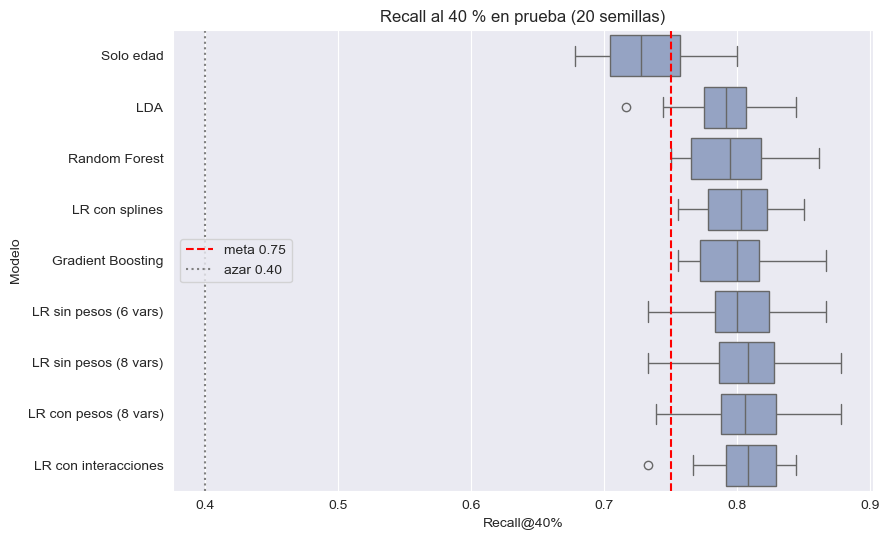

In [ ]:
orden = resumen.sort_values("recall_media").index
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=semillas, y="Modelo", x="Recall@40%", order=orden, color="#8DA0CB", ax=ax)
ax.axvline(META, color="red", ls="--", label="meta 0.75")
ax.axvline(FRACCION, color="gray", ls=":", label="azar 0.40")
ax.set_title("Recall al 40 % en prueba (20 semillas)")
ax.legend(loc="center left")
plt.tight_layout()
plt.savefig(FIG_DIR / "robustez_recall_semillas.png", dpi=150)
plt.show()

In [ ]:
pivote = semillas.pivot(index="Semilla", columns="Modelo", values="Recall@40%")

def contra(base):
    filas = []
    for nombre in pivote.columns:
        if nombre == base:
            continue
        d = pivote[nombre] - pivote[base]
        filas.append({"modelo": nombre, "diferencia_media": d.mean(),
                      "semillas_gana": int((d > 0).sum()), "semillas_empata": int((d == 0).sum()),
                      "p_wilcoxon": stats.wilcoxon(d).pvalue if (d != 0).any() else np.nan})
    return pd.DataFrame(filas).set_index("modelo").round(4)

print("contra solo edad:")
display(contra("Solo edad"))
print("contra LR sin pesos (8 vars):")
display(contra("LR sin pesos (8 vars)"))

contra solo edad:


,diferencia_media,semillas_gana,semillas_empata,p_wilcoxon
modelo,,,,
Gradient Boosting,0.0683,19,0,0.0001
LDA,0.0569,18,1,0.0002
LR con interacciones,0.0758,20,0,0.0001
LR con pesos (8 vars),0.0742,20,0,0.0001
LR con splines,0.0681,20,0,0.0001
LR sin pesos (6 vars),0.0700,20,0,0.0001
LR sin pesos (8 vars),0.0739,20,0,0.0001
Random Forest,0.0644,19,0,0.0001


contra LR sin pesos (8 vars):


,diferencia_media,semillas_gana,semillas_empata,p_wilcoxon
modelo,,,,
Gradient Boosting,-0.0056,6,2,0.1894
LDA,-0.0169,0,1,0.0001
LR con interacciones,0.0019,8,6,0.7038
LR con pesos (8 vars),0.0003,7,8,0.5528
LR con splines,-0.0058,6,1,0.1768
LR sin pesos (6 vars),-0.0039,7,4,0.1606
Random Forest,-0.0094,7,1,0.0695
Solo edad,-0.0739,0,0,0.0001


In [ ]:
semillas.to_csv(FIG_DIR / "robustez_resultados_por_semilla.csv", index=False)
resumen.to_csv(FIG_DIR / "robustez_resumen.csv")
tabla_cv.to_csv(FIG_DIR / "modelos_comparativa_cv.csv")
tabla_test.to_csv(FIG_DIR / "modelos_comparativa_test.csv")
print("tablas guardadas")

tablas guardadas


## 7. Conclusiones

- Los datos cumplen casi todos los supuestos. Las excepciones son la linealidad de edad y colesterol total (afecta a la regresión simple) y la normalidad (afecta al LDA). La independencia se cumple solo en parte por el diseño de NHANES.
- Para el simulador usamos un modelo sin pesos de clase para que las probabilidades sean creíbles.
- Con el umbral de 0,138 se prioriza al 38 % de los adultos y se captura el 80 % de los casos.